
Hyperparameter Performance Summary Table:

 K-Value  Accuracy  Macro F1-Score  Inference Latency (s)
       1  0.810000        0.817732               1.375714
       3  0.817333        0.823802               1.347450
       5  0.826667        0.832167               1.315275
      11  0.826667        0.832166               1.314670


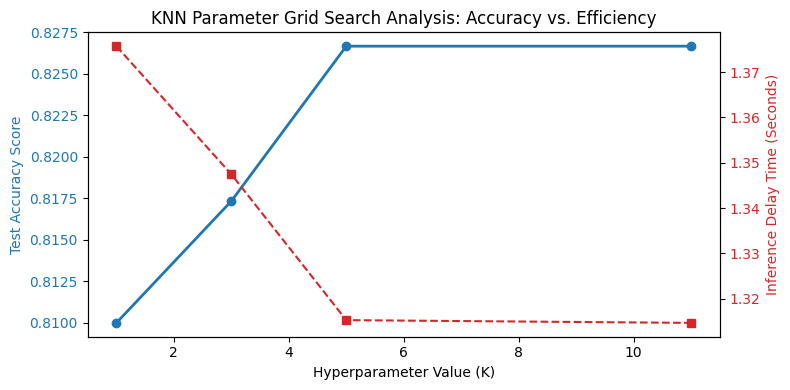

In [7]:

import time
import torchvision
import torchvision.transforms as transforms
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import matplotlib.pyplot as plt

# 1. Download and load data using PyTorch
transform = transforms.Compose([transforms.ToTensor()])
train_dataset = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

# 2. Convert to flattened NumPy arrays
X_train = train_dataset.data.numpy().reshape(-1, 28 * 28)
y_train = train_dataset.targets.numpy()
X_test = test_dataset.data.numpy().reshape(-1, 28 * 28)
y_test = test_dataset.targets.numpy()

# Adjust these values based on your computer's processing power
train_subset_size = 15000
test_subset_size = 1500

X_train_sub = X_train[:train_subset_size] / 255.0
y_train_sub = y_train[:train_subset_size]
X_test_sub = X_test[:test_subset_size] / 255.0
y_test_sub = y_test[:test_subset_size]

k_values = [1, 3, 5, 11]
results = []

for k in k_values:
    # Initialize classifier (using all CPU cores via n_jobs=-1)
    knn = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    knn.fit(X_train_sub, y_train_sub)

    # Measure inference latency explicitly during prediction
    start_time = time.time()
    y_pred = knn.predict(X_test_sub)
    end_time = time.time()

    # Calculate performance metrics
    acc = accuracy_score(y_test_sub, y_pred)
    f1 = f1_score(y_test_sub, y_pred, average='macro')
    test_time = end_time - start_time

    # Append structured dictionary to results list
    results.append({
        'K-Value': k,
        'Accuracy': acc,
        'Macro F1-Score': f1,
        'Inference Latency (s)': test_time
    })

results_df = pd.DataFrame(results)
print('\nHyperparameter Performance Summary Table:\n')
print(results_df.to_string(index=False))

# Plot accuracy and inference latencies
fig, ax1 = plt.subplots(figsize=(8, 4))
color = 'tab:blue'
ax1.set_xlabel('Hyperparameter Value (K)')
ax1.set_ylabel('Test Accuracy Score', color=color)
ax1.plot(results_df['K-Value'], results_df['Accuracy'], marker='o', color=color, linewidth=2)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Inference Delay Time (Seconds)', color=color)
ax2.plot(results_df['K-Value'], results_df['Inference Latency (s)'], marker='s', color=color,
         linestyle='--')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('KNN Parameter Grid Search Analysis: Accuracy vs. Efficiency')
fig.tight_layout()
plt.show()
